## Deterministic dynamics and the Chapman-Kolmogorov equations

We assume the reader is familiar with at least the basic ideas and concepts of the science of dynamics, as would be studied in a first course in physics. The abstract setup is as follows: We imagine some sort of *phase space* $M$ for the dynamical system under study, whose points correspond to the possible states of the system. For example, for a particle moving along a $1$-dimensional axis, we might take $M = \mathbb{R}^2$, where a point $(q,p)\in M$ encodes both the particle's position $q$ and its momentum $p$. (This is the paradigmatic example in Hamiltonian mechanics.)

In deterministic dynamics, the physical laws that govern the time-evolution of states are distilled into a family of functions on the phase space

$$
F_{t_1,t_2}: M \to M,
$$

one for each pair of times $t_1$ and $t_2$ with $t_1 \leq t_2$. For example, if the system is in state $m_1\in M$ at time $t_1$, then its state at some later time $t_2 \geq t_1$ is

$$
m_2 = F_{t_1,t_2}(m_1).
$$

These functions $F_{t_1,t_2}$ are sometimes called *evolution operators*. If one inquires about the *total* time evolution of the system from $t_1$ to a third time $t_3\geq t_2$, we may apply directly the relevant evolution operator to get

$$
m_3 = F_{t_1,t_3}(m_1).
$$

However, we equally well could have applied *two* evolution operators, passing through the intermediate state $m_2$ to get a second state

$$
m_3' = F_{t_2,t_3}\big(F_{t_1,t_2}(m_1)\big)
$$

at time $t_3$. As we explain below, the determinism of the physical laws manifests as the equality of these two states, no matter the intermediate time $t_2$ and intermediate state $m_2$. This yields equations of functions

$$
F_{t_1,t_3} = F_{t_2,t_3} \circ F_{t_1,t_2},
$$

for all $t_1 \leq t_2 \leq t_3$, called the *Chapman-Kolmogorov equations*. (It is also natural to assume that $F_{t,t}(m) = m$, for all $t$ and $m\in M$.)

In what ways do the Chapman-Kolmogorov equations encode a form of "determinism"? The idea is that the future evolution of the system depends only on its *current* state, and not on whatever history led to that state. Suppose, for example, that two different histories bring the system to the same state $m_2$ at time $t_2$ — say, from $m_1$ at time $t_1$, and from $m_1'$ at time $t_1'$, so that

$$
F_{t_1,t_2}(m_1) = F_{t_1',t_2}(m_1') = m_2.
$$

Part of "determinism" should mean that the subsequent evolution of the system, to any later time $t_3\geq t_2$, cannot distinguish between these two histories. Indeed, applying the Chapman-Kolmogorov equations to each history in turn gives

$$
F_{t_1,t_3}(m_1) = F_{t_2,t_3}\big(F_{t_1,t_2}(m_1)\big) = F_{t_2,t_3}(m_2),
$$

$$
F_{t_1',t_3}(m_1') = F_{t_2,t_3}\big(F_{t_1',t_2}(m_1')\big) = F_{t_2,t_3}(m_2),
$$

so both histories yield the *same* state $F_{t_2,t_3}(m_2)$ at time $t_3$. All dependence on the particular history of the system prior to time $t_2$ is invisible, leaving only dependence on the intermediate state $m_2$.

We should say that the Chapman-Kolmogorov equations are not, by themselves, the entire content of determinism. That each $F_{t_1,t_2}$ is a genuine function of $m_1$, rather than a relation admitting several possible outcomes, already encodes the absence of randomness in a single step of the evolution. Chapman-Kolmogorov is the further, independent requirement that these single steps be mutually consistent: That decomposing the evolution from $t_1$ to $t_3$ through any intermediate time $t_2$ recovers the same map $F_{t_1,t_3}$. Without this consistency, one could not speak coherently of a single evolving physical law at all, since the predicted state at $t_3$ would depend on the arbitrary choice of how the time interval was subdivided.

Imagine that, at time $0$, you attempt to predict the future value $X_t$ of a random walk at some future time $t$. From the plots of the trajectories immediately above, it is evident that your prediction will *always* be uncertain, and that this uncertainty grows larger as $t$ increases. The probability distribution that describes this uncertainty is exactly the law of the random variable $X_t$, which we might write as

$$
P(X_t = x \mid X_0 = a)
$$

to emphasize that the random walk starts at $X_0 = a$. When written like this, the law is understood as a *transition probability distribution*, since it gives the probabilities of transitioning from the state $X_0 = a$ at time $0$ to the various possible states $X_t=x$ at time $t$. The fact that this probability distribution "spreads out" as $t$ increases is known as *diffusion*, and it is a fundamental property of random walks and many other stochastic processes.

In fact, if the random walk has probability parameter $p$, then we have

$$
V(\Delta X_t) = V(2B_t - 1) = 4pq,
$$ 

where we set $q=1-p$, and where $B$ is the IID Bernoulli process used to construct the increments in the previous section. Since the increments are independent, it then follows that

$$
V(X_t) = \sum_{s=1}^t V(\Delta X_s) = 4tpq.
$$ {#eq-variance-random-walk}

Thus, the variances of a random walk grow linearly as a function of time $t$. As for the expectations, we have
$$
E(X_t) = X_0 + \sum_{s=1}^t E(\Delta X_s) = X_0 + t(p-q),
$$ {#eq-expectation-random-walk}

so the expectations also grow linearly as a function of time $t$.

These observations, along with the plots in the previous section, suggest that the time-evolution of the law of $X_t$ consists of a "peak" that moves linearly with time (according to the expectation) while simultaneously diffusing (according to the variance).

This evolution may be observed experimentally in SigAlg, as shown in the following plot. We simulate 10,000 trajectories of a random walk with $p=0.7$ and then plots histograms of the values of $X_t$ for various $t$ in a "ridgeline" plot:

NameError: name 'yellow' is not defined

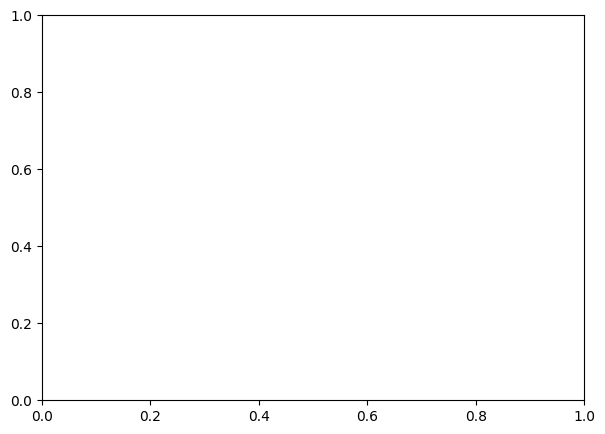

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

T = sa.Time.discrete(length=200)

X = sa.RandomWalk.generate(
    p=0.7,
    mode="sim",
    n_trajectories=10_000,
    index=T,
    random_state=42,
)
P = X.measure

_, ax = plt.subplots(figsize=(7, 5))

n_plots = 8
time_step = 25  # 200 = 8 * 25

times = [time_step * k for k in range(1, n_plots + 1)]
cmap = LinearSegmentedColormap.from_list("conditional_cmap", [yellow, purple, blue])
colors = [cmap(i / (n_plots - 1)) for i in range(n_plots)]

for color, t_1 in zip(colors, times):
    probabilities = (P >> X[t_1 - 1]).data

    ax.bar(
        x=probabilities.index,
        height=-probabilities.values * 175,
        width=0.8,
        color=color,
        bottom=t_1,
    )

ax.invert_yaxis()
ax.set_xlabel("state")
ax.set_ylabel("time")
ax.set_title(
    "Time-evolution of the probability distribution\nof a random walk",
)
plt.tight_layout()
plt.show()

As we expected, the peak of the distribution drifts toward higher values as time increases, while simultaneously diffusing.

It is not difficult to write down a formula for the last of $X_t$; in fact, we accomplish this in [@thm-explicit-discrete-law]. However, it is also possible to describe the time-evolution of the law of $X_t$ using a special *difference equation*, which is the discrete starting point for the Fokker-Planck partial differential equation that we will study later.

::: {#thm-discrete-diffusion-equation}
## Discrete Diffusion Equation

Let $X$ be a random walk with probability parameter $p$, starting at position $a$, and write $q=1-p$. If we write

$$
f(x,t) = P(X_t = x)
$$

for the probability function of $X_t$, then for all integers $t \geq 0$ and all $x \in \mathbb{Z}$, we have
$$
f(x,t+1) - f(x,t) = p \big( f(x-1,t) - f(x,t) \big) + q \big( f(x+1,t) - f(x,t) \big),
$$

along with the initial conditions
$$
f(a, 0) = 1, \quad f(x,0) = 0 \text{ for } x \neq a.
$$
:::

::: {.callout-note collapse="true" icon="false"}
## Proof.
From the law of total probability, we have

$$
P(X_{t+1}=x) = \sum_{y\in \mathbb{Z}} P(X_{t+1}=x \mid X_t = y) P(X_t = y).
$$

However, the conditional probabilities on the right-hand vanish except when $y = x-1$ or $y = x+1$, since the random walk can only move one unit to the left or right at each time step. Thus, we have

$$
f(x,t+1) = p f(x-1,t) + q f(x+1,t).
$$

Then, if we subtract $f(x,t)$ from both sides and use that $p+q=1$, we get

$$
f(x,t+1) - f(x,t) = p \big( f(x-1,t) - f(x,t) \big) + q \big( f(x+1,t) - f(x,t) \big),
$$

as claimed.
:::

Thus, the (forward) time increment of the probability function $f(x,t)$ is given by a weighted sum of the spatial increments to the left and right, with weights given by the probabilities $p$ and $q$. We will see this same sort of structure in the Fokker-Planck equation, where a time derivative is equal to an expression involving spatial derivatives.




::: {#thm-explicit-discrete-law}
## Law of Random Walk
Let $X$ be a random walk with probability parameter $p$, starting position $a$, and write $q=1-p$. Then the probability function $f(x,t)$ of $X_t$ is given by the formula

$$
f(x,t) = \binom{t}{\frac{x-a+t}{2}} p^{\frac{x-a+t}{2}} q^{\frac{t-x+a}{2}},
$$

for all integers $t\geq 0$ and all

$$
x \in \{ a-t, a-t+2, a-t+4, \ldots, a+t \}.
$$
:::

::: {.callout-note collapse="true" icon="false"}
## Proof.

For each integer $t\geq 1$, we have that

$$
X_t = a + \sum_{s=1}^t \Delta X_s = a + \sum_{s=1}^t (2B_s - 1) = a-t + 2Y,
$$

where $Y$ is a binomial random variable with parameters $t$ and $p$. Then $X_t=x$ if and only if $Y = \frac{x - a + t}{2}$, so the result follows from the probability function of the binomial distribution.
:::